# PCD_Assignment03
Adaptive mean thresholding dan morfologi biner.

Dataset: [Magnetic Tile Defect](https://github.com/abin24/Magnetic-tile-defect-datasets.)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from io import BytesIO
from pathlib import PurePosixPath
import zipfile
from google.colab import files
from IPython.display import display


In [2]:
uploaded = files.upload()
data = {}

for name, content in uploaded.items():
    if name.lower().endswith('.zip'):
        with zipfile.ZipFile(BytesIO(content)) as archive:
            for item in archive.infolist():
                if not item.is_dir() and '__MACOSX' not in item.filename:
                    data[PurePosixPath(item.filename).name] = archive.read(item)
    else:
        data[name] = content

images = {}
for name in sorted(data):
    if name.lower().endswith(('.jpg', '.jpeg')):
        stem = PurePosixPath(name).stem
        mask_name = stem + '.png'
        if mask_name not in data:
            raise ValueError(f'Mask {mask_name} belum diupload.')
        rgb = np.array(Image.open(BytesIO(data[name])).convert('RGB'))
        gray = np.rint(0.299 * rgb[:, :, 0] + 0.587 * rgb[:, :, 1]
                       + 0.114 * rgb[:, :, 2]).astype(np.uint8)
        mask = np.array(Image.open(BytesIO(data[mask_name])).convert('L'))
        gt = mask > 0 if mask.max() <= 1 else mask >= 128
        if gray.shape != gt.shape:
            raise ValueError(f'Ukuran citra dan mask berbeda: {stem}')
        images[stem] = {'gray': gray, 'gt': gt}

if not images:
    raise ValueError('Upload ZIP atau pasangan JPG dan PNG mask.')


Saving exp6_num_3789.png to exp6_num_3789.png
Saving exp6_num_3789.jpg to exp6_num_3789.jpg
Saving exp5_num_5022.png to exp5_num_5022.png
Saving exp5_num_5022.jpg to exp5_num_5022.jpg
Saving exp5_num_262654.png to exp5_num_262654.png
Saving exp5_num_262654.jpg to exp5_num_262654.jpg
Saving exp3_num_54291.png to exp3_num_54291.png
Saving exp3_num_54291.jpg to exp3_num_54291.jpg
Saving exp1_num_290998.png to exp1_num_290998.png
Saving exp1_num_290998.jpg to exp1_num_290998.jpg


### Segmentasi dan morfologi


In [3]:
def adaptive_threshold(gray, window, C):
    p = window // 2
    padded = np.pad(gray.astype(float), p, mode='reflect')
    integral = np.pad(padded.cumsum(0).cumsum(1), ((1, 0), (1, 0)))
    total = (integral[window:, window:] - integral[:-window, window:]
             - integral[window:, :-window] + integral[:-window, :-window])
    mean = total / window ** 2
    return gray < mean - C


In [4]:
def dilation(mask, kernel):
    h, w = mask.shape
    p = kernel.shape[0] // 2
    padded = np.pad(mask, p, constant_values=False)
    result = np.zeros_like(mask, dtype=bool)
    for y, x in np.argwhere(kernel[::-1, ::-1]):
        result |= padded[y:y+h, x:x+w]
    return result


def erosion(mask, kernel):
    h, w = mask.shape
    p = kernel.shape[0] // 2
    padded = np.pad(mask, p, constant_values=False)
    result = np.ones_like(mask, dtype=bool)
    for y, x in np.argwhere(kernel):
        result &= padded[y:y+h, x:x+w]
    return result


def opening(mask, kernel):
    p = kernel.shape[0] // 2
    padded = np.pad(mask, p, constant_values=False)
    result = dilation(erosion(padded, kernel), kernel)
    return result[p:-p, p:-p]


def closing(mask, kernel):
    p = kernel.shape[0] // 2
    padded = np.pad(mask, p, constant_values=False)
    result = erosion(dilation(padded, kernel), kernel)
    return result[p:-p, p:-p]


def process(mask, kernel):
    opened = opening(mask, kernel)
    return {'Awal': mask,
            'Erosion': erosion(mask, kernel),
            'Dilation': dilation(mask, kernel),
            'Opening': opened,
            'Closing': closing(mask, kernel),
            'Opening + Closing': closing(opened, kernel)}


In [5]:
def metrics(pred, gt):
    tp = np.count_nonzero(pred & gt)
    fp = np.count_nonzero(pred & ~gt)
    fn = np.count_nonzero(~pred & gt)
    union = tp + fp + fn
    return {'IoU': tp / union if union else 1.0,
            'Precision': tp / max(tp + fp, 1),
            'Recall': tp / max(tp + fn, 1)}


In [6]:
calibration_id = 'exp3_num_54291'
cal = images[calibration_id]
evaluation_ids = [name for name in images if name != calibration_id]

candidates = []
for window in [15, 31, 51]:
    for C in [5, 7, 10, 15]:
        pred = adaptive_threshold(cal['gray'], window, C)
        candidates.append((metrics(pred, cal['gt'])['IoU'], window, C))

_, window, C = max(candidates, key=lambda row: row[0])
raw_cal = adaptive_threshold(cal['gray'], window, C)

kernels = {
    'cross3': np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]], dtype=bool),
    'square3': np.ones((3, 3), dtype=bool),
    'square5': np.ones((5, 5), dtype=bool)
}
kernel_scores = {}
for name, kernel in kernels.items():
    pred = closing(opening(raw_cal, kernel), kernel)
    kernel_scores[name] = metrics(pred, cal['gt'])['IoU']

kernel_name = max(kernel_scores, key=kernel_scores.get)
kernel = kernels[kernel_name]
display(pd.DataFrame([{'Kalibrasi': calibration_id, 'Window': window,
                       'C': C, 'Kernel': kernel_name}]))


,Kalibrasi,Window,C,Kernel
0,exp3_num_54291,15,15,square5


### Hasil


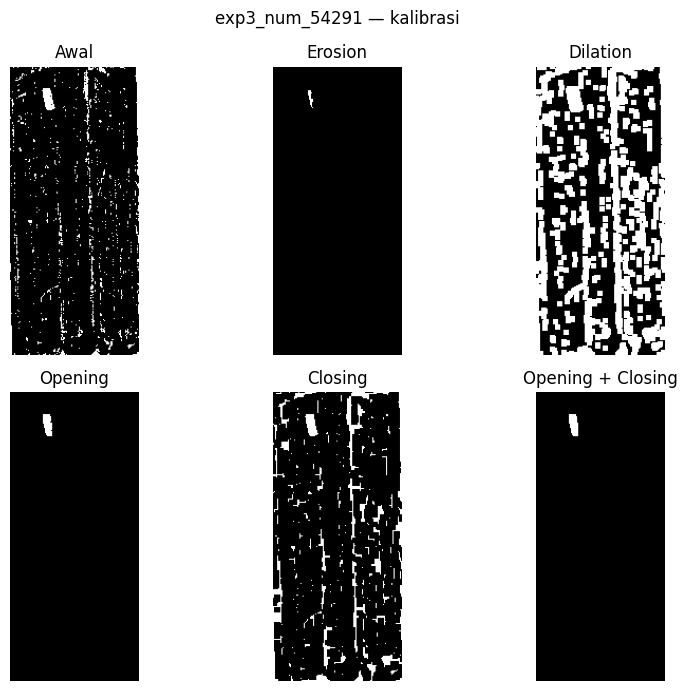

In [7]:
cal_results = process(raw_cal, kernel)
fig, axes = plt.subplots(2, 3, figsize=(9, 7))
for ax, (name, mask) in zip(axes.flat, cal_results.items()):
    ax.imshow(mask, cmap='gray', vmin=0, vmax=1)
    ax.set_title(name)
    ax.axis('off')
fig.suptitle(calibration_id + ' — kalibrasi')
plt.tight_layout()
plt.show()


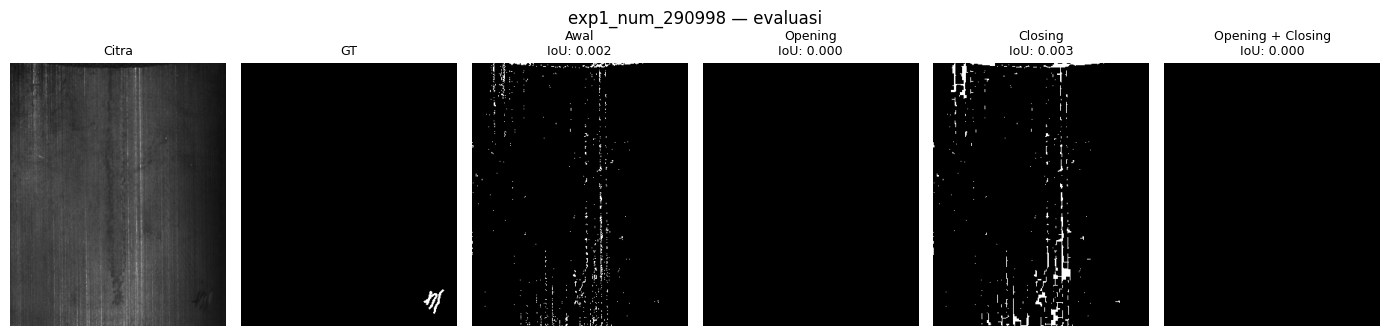

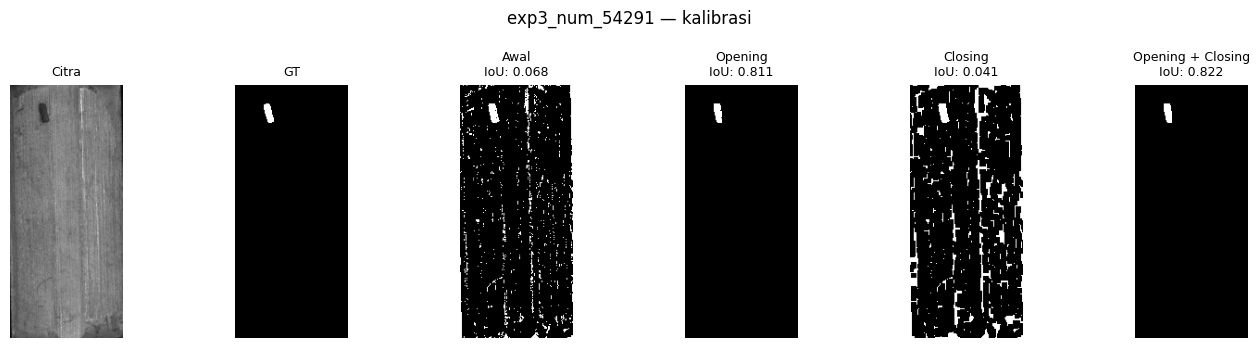

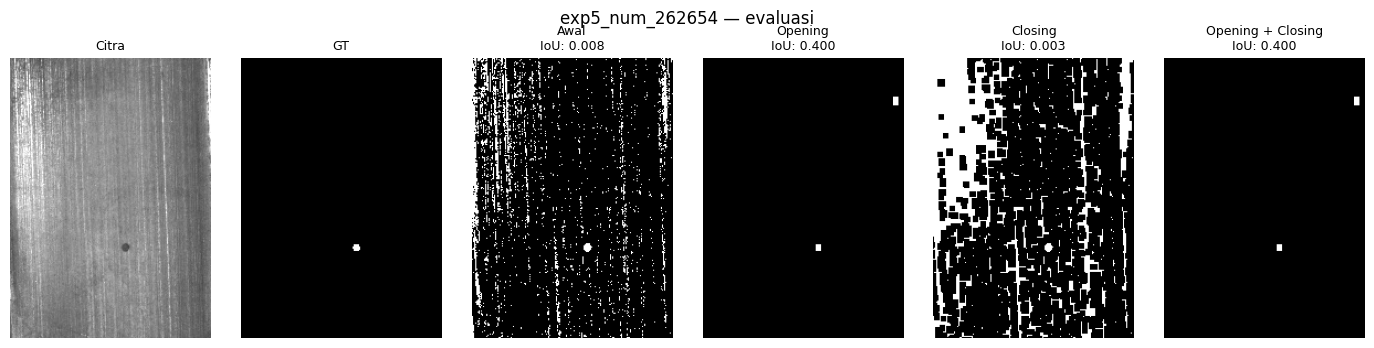

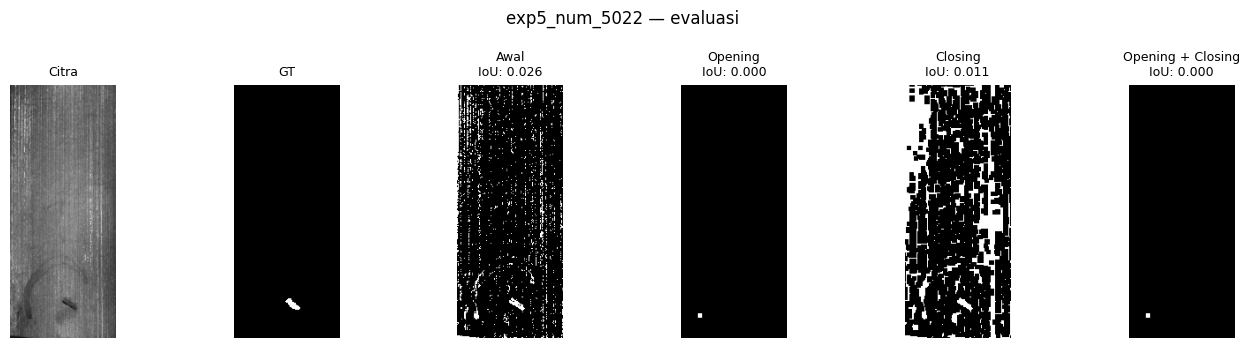

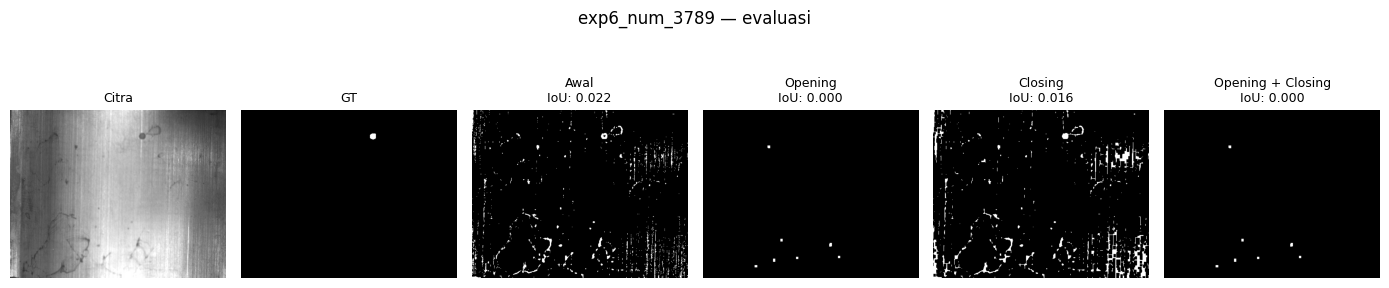

In [8]:
plt.close('all')

methods = ['Awal', 'Opening', 'Closing', 'Opening + Closing']
results = {}
rows = []

for name, image in images.items():
    raw = adaptive_threshold(image['gray'], window, C)
    results[name] = process(raw, kernel)
    role = 'Kalibrasi' if name == calibration_id else 'Evaluasi'

    panels = [('Citra', image['gray']), ('GT', image['gt'])]

    for method in methods:
        pred = results[name][method]
        score = metrics(pred, image['gt'])
        rows.append({
            'Citra': name,
            'Peran': role,
            'Metode': method,
            **score
        })
        panels.append((f"{method}\nIoU: {score['IoU']:.3f}", pred))

    fig, axes = plt.subplots(1, 6, figsize=(14, 3.5))

    for i, (ax, (title, panel)) in enumerate(zip(axes, panels)):
        ax.imshow(
            panel,
            cmap='gray',
            vmin=0,
            vmax=255 if i == 0 else 1
        )
        ax.set_title(title, fontsize=9)
        ax.axis('off')

    fig.suptitle(name + ' — ' + role.lower())
    plt.tight_layout()
    plt.show()
    plt.close(fig)

In [9]:
scores = pd.DataFrame(rows)
display(scores.round(4))

evaluation = scores[scores['Peran'] == 'Evaluasi']
display(evaluation.groupby('Metode', sort=False)[['IoU', 'Precision', 'Recall']]
        .mean().round(4))


,Citra,Peran,Metode,IoU,Precision,Recall
0,exp1_num_290998,Evaluasi,Awal,0.0022,0.0025,0.0142
1,exp1_num_290998,Evaluasi,Opening,0.0000,0.0000,0.0000
2,exp1_num_290998,Evaluasi,Closing,0.0029,0.0032,0.0320
3,exp1_num_290998,Evaluasi,Opening + Closing,0.0000,0.0000,0.0000
4,exp3_num_54291,Kalibrasi,Awal,0.0678,0.0679,0.9869
5,exp3_num_54291,Kalibrasi,Opening,0.8107,0.8954,0.8954
6,exp3_num_54291,Kalibrasi,Closing,0.0411,0.0411,1.0000
7,exp3_num_54291,Kalibrasi,Opening + Closing,0.8225,0.8968,0.9085
8,exp5_num_262654,Evaluasi,Awal,0.0076,0.0076,1.0000
9,exp5_num_262654,Evaluasi,Opening,0.4000,0.4286,0.8571


,IoU,Precision,Recall
Metode,,,
Awal,0.0145,0.0147,0.6461
Opening,0.1000,0.1071,0.2143
Closing,0.0081,0.0082,0.6903
Opening + Closing,0.1000,0.1071,0.2143


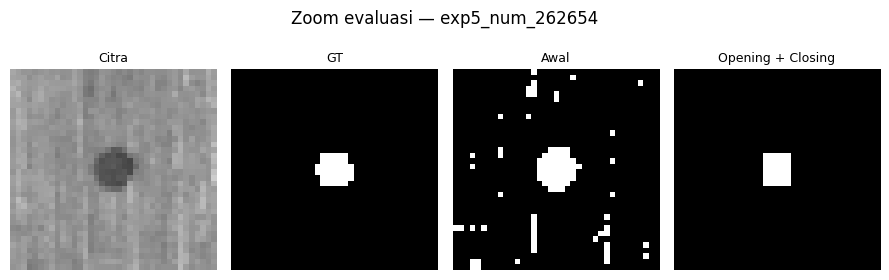

In [10]:
zoom_id = 'exp5_num_262654'
image = images[zoom_id]
y, x = np.where(image['gt'])
y0, y1 = max(0, y.min() - 15), min(image['gray'].shape[0], y.max() + 16)
x0, x1 = max(0, x.min() - 15), min(image['gray'].shape[1], x.max() + 16)
region = np.s_[y0:y1, x0:x1]
panels = [('Citra', image['gray']), ('GT', image['gt']),
          ('Awal', results[zoom_id]['Awal']),
          ('Opening + Closing', results[zoom_id]['Opening + Closing'])]

fig, axes = plt.subplots(1, 4, figsize=(9, 3))
for i, (ax, (title, panel)) in enumerate(zip(axes, panels)):
    ax.imshow(panel[region], cmap='gray', vmin=0, vmax=255 if i == 0 else 1,
              interpolation='nearest')
    ax.set_title(title, fontsize=9)
    ax.axis('off')
fig.suptitle('Zoom evaluasi — ' + zoom_id)
plt.tight_layout()
plt.show()
